# Word-Level LSTM Language Model for Book Titles

Train an LSTM that predicts the next word of a book title, evaluate it with top-k accuracy and perplexity, and use it to generate new titles. The second half improves the model (masking, shorter sequences, an out-of-vocabulary token) and the decoding (temperature, top-k sampling, blocking `<unk>`).

**Data:** the 10,000 book titles in the goodbooks-10k dataset.

## Part 1: Data Loading and Initial Exploration

In this section, we load and explore the dataset containing book titles. The key steps performed include:

1. **Loading the Dataset**: The dataset is loaded directly from a URL into a pandas DataFrame.
2. **Basic Information Display**: Basic information about the dataset, including column names and sample data, is displayed.
3. **Title Preprocessing**: Titles are preprocessed by converting them to lowercase and removing non-alphabetic characters.
4. **Title Length Calculation**: The length of each title (in terms of the number of words) is calculated, and basic statistics are displayed.
5. **Visualization**: The distribution of title lengths is plotted using a histogram and box plot, and a word cloud is generated to visualize the most common words in the book titles.


### More on GoodBooks10K Dataset

The **GoodBooks10K** dataset is a comprehensive collection of user ratings, reviews, and metadata for 10,000 books. It is commonly used for recommender systems research and analysis. The dataset includes:

- **Books metadata**: Titles, authors, genres, and publication information.
- **User interactions**: Ratings (1-5 scale) and textual reviews.
- **Additional features**: Tags and user-generated lists.

This dataset provides a rich resource for exploring collaborative filtering, natural language processing, and book-related data analysis.

For more information and to access the dataset, visit the [Kaggle page](https://www.kaggle.com/datasets/zygmunt/goodbooks-10k/).

For insights into advanced recommendation system research, refer to NVIDIA's paper on **Deep Learning-Based Recommender Systems** ([arXiv:1911.12391](https://arxiv.org/pdf/1911.12391)).

Dataset loaded successfully!
Columns: Index(['book_id', 'goodreads_book_id', 'best_book_id', 'work_id',
       'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year',
       'original_title', 'title', 'language_code', 'average_rating',
       'ratings_count', 'work_ratings_count', 'work_text_reviews_count',
       'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5',
       'image_url', 'small_image_url'],
      dtype='object')

Sample Data:
   book_id  goodreads_book_id  best_book_id  work_id  books_count       isbn  \
0        1            2767052       2767052  2792775          272  439023483   
1        2                  3             3  4640799          491  439554934   
2        3              41865         41865  3212258          226  316015849   
3        4               2657          2657  3275794          487   61120081   
4        5               4671          4671   245494         1356  743273567   

         isbn13                      authors 

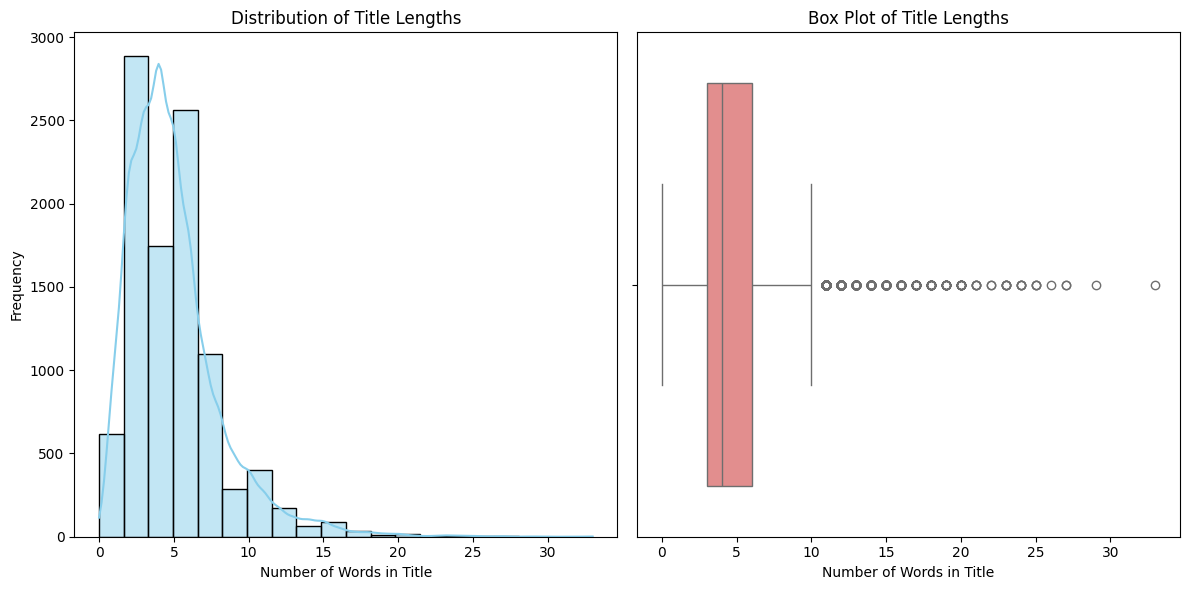

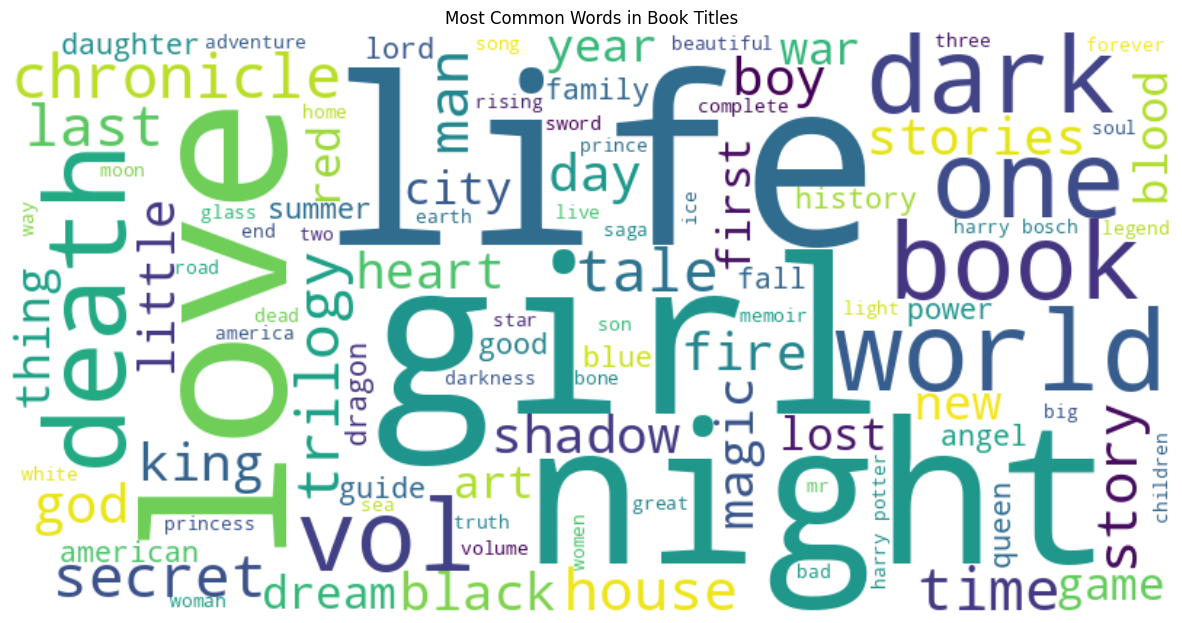

In [1]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
%pip install seaborn
import seaborn as sns

# URL of the dataset
dataset_url = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/books.csv"

# Load the dataset directly into a pandas DataFrame
df = pd.read_csv(dataset_url)

# Display basic information about the dataset
print("Dataset loaded successfully!")
print("Columns:", df.columns)
print("\nSample Data:")
print(df.head())

# Extract titles
titles = df['title']

# Preprocess the titles
def preprocess_title(title):
    title = title.lower()  # Convert to lowercase
    title = ''.join(char if char.isalpha() or char.isspace() else '' for char in title)  # Keep only letters and spaces
    return title

df['cleaned_title'] = titles.apply(preprocess_title)

# Calculate title lengths (number of words)
df['title_length'] = df['cleaned_title'].apply(lambda x: len(x.split()))

# Display statistics
average_length = df['title_length'].mean()
print(f"\nNumber of titles: {len(df)}")
print(f"Average title length: {average_length:.2f} words")
print("\nSample cleaned titles:")
print(df[['title', 'cleaned_title', 'title_length']].head())

# Improved histogram and box plot
plt.figure(figsize=(12, 6))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(df['title_length'], bins=20, kde=True, color="skyblue", edgecolor='black')
plt.title('Distribution of Title Lengths')
plt.xlabel('Number of Words in Title')
plt.ylabel('Frequency')

# Box plot
plt.subplot(1, 2, 2)
sns.boxplot(x=df['title_length'], color="lightcoral")
plt.title('Box Plot of Title Lengths')
plt.xlabel('Number of Words in Title')

plt.tight_layout()
plt.show()

# Generate a word cloud
all_words = ' '.join(df['cleaned_title'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(all_words)

# Plot the word cloud
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Most Common Words in Book Titles')
plt.show()

In [2]:
print(df[['title', 'cleaned_title', 'title_length']].head())

                                               title  \
0            The Hunger Games (The Hunger Games, #1)   
1  Harry Potter and the Sorcerer's Stone (Harry P...   
2                            Twilight (Twilight, #1)   
3                              To Kill a Mockingbird   
4                                   The Great Gatsby   

                                       cleaned_title  title_length  
0                 the hunger games the hunger games              6  
1  harry potter and the sorcerers stone harry pot...             8  
2                                 twilight twilight              2  
3                              to kill a mockingbird             4  
4                                   the great gatsby             3  


## Part 2: Data Preparation

In this section, we prepare the data for training the LSTM-based language model. The key steps performed include:

1. **Tokenizing Text Data**: The text data is tokenized and converted into sequences of numerical values.
2. **Padding Sequences**: The sequences are padded to ensure consistent input size for the model.
3. **Preparing Training and Target Data**: The training and target data are prepared with one-hot encoding for categorical predictions.

The parameters `MAX_WORDS` and `MAX_LENGTH` are defined to restrict the tokenizer to consider only the top 2500 most frequent words and to specify the maximum length of the sequences generated, respectively.

The dataset is split into training and testing sets. The text data is tokenized, and input sequences are created. These sequences are then padded to ensure consistent input size. Finally, the predictors and targets are created, and the target data is one-hot encoded for categorical predictions.

In [3]:
%pip install tensorflow
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras import utils
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# Parameters
MAX_WORDS = 2500  # Limit vocabulary size
MAX_LENGTH = 20    # Max sequence length

# Split the dataset
train_titles, test_titles = train_test_split(df['cleaned_title'].dropna(), test_size=0.2, random_state=42)

# Tokenize and prepare training data
tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(train_titles)
train_sequences = tokenizer.texts_to_sequences(train_titles)
test_sequences = tokenizer.texts_to_sequences(test_titles)


# Create sequences for training and testing
def create_sequences(sequences, max_length):
    input_sequences = []
    for sequence in sequences:
        for i in range(1, max_length):
            n_gram_sequence = sequence[:i+1]
            input_sequences.append(n_gram_sequence)
    return input_sequences

# Generate input sequences
train_input_sequences = create_sequences(train_sequences, MAX_LENGTH)
test_input_sequences = create_sequences(test_sequences, MAX_LENGTH)

# Pad sequences
train_padded = pad_sequences(train_input_sequences, maxlen=MAX_LENGTH, padding='pre')
test_padded = pad_sequences(test_input_sequences, maxlen=MAX_LENGTH, padding='pre')

# Create predictors and targets
X_train = train_padded[:, :-1]
y_train = train_padded[:, -1]
X_test = test_padded[:, :-1]
y_test = test_padded[:, -1]

# One-hot encode the target
y_train = utils.to_categorical(y_train, num_classes=MAX_WORDS)
y_test = utils.to_categorical(y_test, num_classes=MAX_WORDS)

print(f'Vocabulary size: {len(tokenizer.word_index)}')
print(f'Number of train sequences: {len(train_input_sequences)}')
print(f'Number of test sequences: {len(test_input_sequences)}')

Vocabulary size: 8260
Number of train sequences: 152000
Number of test sequences: 38000


## Part 3: Model design and training
### LSTM-based language model

Embedding(2500 words, 100 dimensions), LSTM(100, returns sequences), Dropout(0.2), LSTM(100), Dropout(0.2), Dense(2500, softmax). Adam optimizer, categorical cross-entropy, 10 epochs, batch size 48, with 20% of the training sequences held out for validation. Trained on a Colab T4 GPU.

In [4]:
import tensorflow as tf

# Check if GPU is available
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout

# Define model
model = Sequential()
model.add(Embedding(input_dim=MAX_WORDS, output_dim=100))
model.add(LSTM(100, return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(100))
model.add(Dropout(0.2))
model.add(Dense(MAX_WORDS, activation='softmax'))

# Compile model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, epochs=10, validation_split=0.2, batch_size=48)

Epoch 1/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.1144 - loss: 5.8752 - val_accuracy: 0.1343 - val_loss: 6.5495
Epoch 2/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.1802 - loss: 4.8202 - val_accuracy: 0.1630 - val_loss: 6.6734
Epoch 3/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.2630 - loss: 4.1073 - val_accuracy: 0.1919 - val_loss: 6.9998
Epoch 4/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 29s 12ms/step - accuracy: 0.3539 - loss: 3.5700 - val_accuracy: 0.2005 - val_loss: 7.4121
Epoch 5/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.4327 - loss: 3.1719 - val_accuracy: 0.2115 - val_loss: 7.8641
Epoch 6/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.4901 - loss: 2.8881 - val_accuracy: 0.2141 - val_loss: 8.2549
Epoch 7/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.5322 - loss: 2.6811 - val_accuracy: 0.2256 - val_loss: 8.6015
Epoch 8/10
2534/2534 ━━━━━━━━━━━━━━━━━━━━ 27s 11ms/step - accuracy: 0.5656 -

## Part 4: Inference and Evaluation
### 4.1 Predicting the Next Word and Top-N Words

The code below defines two functions, `predict_next_word` and `predict_top_n_words`, which are used to predict the next word in a sequence based on a trained language model.

1. **Function: `predict_next_word`**
    - **Input**: Takes a trained model, tokenizer, input text, and maximum sequence length.
    - **Process**:
      - Converts the input text to lowercase.
      - Transforms the text into a sequence of integers using the tokenizer.
      - Pads the sequence to ensure it matches the required input length for the model.
      - Uses the model to predict the next word in the sequence.
      - Finds the word corresponding to the highest predicted probability.
    - **Output**: Returns the predicted next word.

2. **Function: `predict_top_n_words`**
    - **Input**: Takes a trained model, tokenizer, input text, maximum sequence length, and the number of top predictions (`n`).
    - **Process**:
      - Converts the input text to lowercase.
      - Transforms the text into a sequence of integers using the tokenizer.
      - Pads the sequence to ensure it matches the required input length for the model.
      - Uses the model to predict the probabilities of the next word.
      - Retrieves the top `n` words with the highest predicted probabilities.
    - **Output**: Returns a list of tuples containing the top `n` predicted words and their corresponding probabilities.

3. **Testing the Predictions**
    - The code tests the `predict_top_n_words` function with the input text "The perfect book for" and retrieves the top 3 predicted words along with their probabilities.
    - The results are printed in the format: `Word: <word>, Probability: <probability>`.

In [6]:
import numpy as np

def predict_next_word(model, tokenizer, text, max_length):
    # Preprocess the input text
    text = text.lower()
    sequence = tokenizer.texts_to_sequences([text])[0]
    sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

    # Predict the next word
    predicted = model.predict(sequence, verbose=0)
    predicted_word_index = np.argmax(predicted, axis=-1)[0]

    # Convert the predicted index to word
    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            return word
    return None

def predict_top_n_words(model, tokenizer, text, max_length, n=3):
    # Preprocess the input text
    text = text.lower()
    sequence = tokenizer.texts_to_sequences([text])[0]
    sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

    # Predict the next word probabilities
    predicted = model.predict(sequence, verbose=0)

    # Get the top n predictions
    top_n_indices = np.argsort(predicted[0])[-n:][::-1]
    top_n_predictions = [(tokenizer.index_word[index], predicted[0][index]) for index in top_n_indices]

    return top_n_predictions

# Test predictions
top_predictions = predict_top_n_words(model, tokenizer, 'The perfect book for', MAX_LENGTH, n=3)
for word, prob in top_predictions:
    print(f"Word: {word}, Probability: {prob:.4f}")

Word: ohare, Probability: 0.9054
Word: hobbes, Probability: 0.0194
Word: poems, Probability: 0.0153


### 4.2 Evaluation Metrics for Language Models

To evaluate the performance of our language model, we use the following metrics:

#### a. Top-1 Accuracy
- **Definition**: Measures the percentage of cases where the model's highest-probability prediction matches the correct word.
- **Purpose**: Indicates how often the model predicts the correct word as its first choice.
- **Interpretation**: Higher values mean the model is better at predicting the correct next word directly.

#### b. Top-5 Accuracy
- **Definition**: Measures the percentage of cases where the correct word is among the top 5 predictions made by the model.
- **Purpose**: Evaluates the model's ability to capture the correct word within a small set of candidates.
- **Interpretation**: Useful in applications like auto-suggestions or autocomplete where multiple suggestions are presented.

#### c. Perplexity
- **Definition**: Exponential of the average negative log-likelihood of the predicted probabilities for the correct words.
- **Purpose**: Captures the model's uncertainty; lower perplexity indicates better confidence and alignment with the true distribution.
- **Interpretation**: Lower values are better, as they indicate the model assigns higher probabilities to correct predictions.

#### d. BLEU Score
- **Definition**: A metric for comparing generated sequences to a reference sequence, focusing on n-gram overlap.
- **Purpose**: Evaluates the quality of text generation, often used in tasks like machine translation.
- **Interpretation**: Scores range from 0 to 1, with higher values indicating better alignment between predicted and reference sequences.

#### Why These Metrics?
- **Top-k Accuracy**: Provides a straightforward measure of correctness and relevance of predictions.
- **Perplexity**: Reflects the confidence of the model in its predictions and overall language understanding.
- **BLEU Score**: Assesses how well the generated text matches expected outputs, making it a valuable metric for creative text generation tasks.

These metrics together offer a comprehensive evaluation of the language model's performance across accuracy, confidence, and output quality.


In [7]:
from sklearn.metrics import accuracy_score
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import numpy as np

def evaluate_model_simple(model, tokenizer, X_test, y_test, max_length, top_k=(1, 5)):
    """
    Evaluate the model on test data using Top-k Accuracy, Perplexity, and BLEU Score.

    Args:
        model: Trained model.
        tokenizer: Fitted tokenizer for converting word indices.
        X_test: Test input data (padded sequences).
        y_test: Test target data (one-hot encoded).
        max_length: Maximum sequence length for padding.
        top_k: Tuple of integers for Top-k accuracy calculations.

    Returns:
        A dictionary with calculated metrics.
    """
    # Convert y_test from one-hot encoding to integer indices
    y_test_indices = np.argmax(y_test, axis=1)

    # Predict probabilities for the test set
    predictions = model.predict(X_test, verbose=0)

    # Create reverse word index
    reverse_word_index = {v: k for k, v in tokenizer.word_index.items()}

    # Top-k Accuracy Calculation
    top_k_accuracies = {}
    for k in top_k:
        top_k_preds = np.argsort(predictions, axis=-1)[:, -k:]
        correct = sum(1 for i in range(len(y_test)) if y_test_indices[i] in top_k_preds[i])
        top_k_accuracies[f"Top-{k} Accuracy"] = correct / len(y_test)

    # Perplexity Calculation
    log_probabilities = -np.log(np.sum(predictions * y_test, axis=1) + 1e-9)
    perplexity = np.exp(np.mean(log_probabilities))

    # BLEU Score Calculation with Smoothing
    bleu_scores = []
    smoothing_function = SmoothingFunction().method1  # Use smoothing function to avoid warnings

    for i in range(len(X_test)):
        reference_word_index = y_test_indices[i]
        predicted_word_index = np.argmax(predictions[i])

        # Skip if indices are not in vocabulary
        if reference_word_index not in reverse_word_index or predicted_word_index not in reverse_word_index:
            continue

        reference_word = [reverse_word_index[reference_word_index]]
        candidate_word = [reverse_word_index[predicted_word_index]]

        # Calculate BLEU score for unigram with smoothing
        bleu_scores.append(sentence_bleu([reference_word], candidate_word, weights=(1, 0, 0, 0), smoothing_function=smoothing_function))
    bleu_score = np.mean(bleu_scores) if bleu_scores else 0.0

    # Combine results into a dictionary
    results = {
        **top_k_accuracies,
        "Perplexity": perplexity,
        "BLEU Score": bleu_score
    }

    return results

# Example usage
results = evaluate_model_simple(model, tokenizer, X_test, y_test, MAX_LENGTH)

# Print results
print("Model Evaluation Metrics:")
for metric, value in results.items():
    print(f"{metric}: {value:.2f}")

Model Evaluation Metrics:
Top-1 Accuracy: 0.25
Top-5 Accuracy: 0.35
Perplexity: 1896.31
BLEU Score: 0.19


## Part 5: Text generation and improvements

### 5.1 Generating titles with greedy decoding
`generate_text` repeatedly predicts the next word with argmax and appends it to the text, for a fixed number of words. Seed: "In the world of AI".

In [8]:
def generate_text(model, tokenizer, seed_text, max_length, num_words):
    result = seed_text

    # since we have to generate N = num_words, we run for loop for that many times; here we don't have
    # an <end> tag to logically stop so we use for loop
    for _ in range(num_words):
        # Preprocess the input text
        # seed_text is the starting phrase (iteration 1)
        result = result.lower()

        # 'texts_to_sequences' converts word into list of ids; returning first list from list of list hence [0]
        sequence = tokenizer.texts_to_sequences([result])[0]

        # padding the list so that all list sequence are of uniform length
        # note: we pad of max_length - 1, not max_length because while training
        # each padding was of length max_length which was split into X (all but last; i.e input words) and y (last; output predicted word)
        # here during training, X has width MAX_LENGTH - 1, not MAX_LENGTH
        # so here during generation; our input must match the width the model was trained on. The model expects MAX_LENGTH - 1 columns
        sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

        # Predict the next word and convert to text
        predicted = model.predict(sequence, verbose=0)

        # our predicted word would have highest probability, so we do argmax on list of token ids
        # we do [0] since it returns a list
        # axis=-1 means “argmax across the 2500 probabilities,” not across rows
        predicted_word_index = np.argmax(predicted, axis=-1)[0]

        # Convert the predicted index to word and add to the result
        word = tokenizer.index_word[predicted_word_index]
        result = result + ' ' + word


    return result

# Generate 5 words iteratively
seed_text = "In the world of AI"
generated_text = generate_text(model, tokenizer, seed_text, MAX_LENGTH, 5)
print(generated_text)

# My observations
# One important fact I observed; every time I run this function, I always get the same output, this is because
# The model weights do not change between runs; same weights plus same input produce the same 2500 probabilities, every time
# Hence this system is deterministic right now since argmax on the same probabilities returns the same id, deterministically.
# To make this truly undeterministic, we should use temperature to increase randomness

in the world of ai owls the rat of the


### 5.2 Temperature sampling

Temperature reshapes the predicted distribution before sampling:
$$
\text{scaled probabilities} = \frac{\exp(\log(\text{probabilities}) / T)}{\sum \exp(\log(\text{probabilities}) / T)}
$$
The next word is then sampled from the scaled distribution instead of taking the argmax. Tested with T = 0.2, 1.0 and 2.0 on the seed "The perfect book for".

In [9]:
import numpy as np

def generate_text_with_temperature(model, tokenizer, seed_text, max_length, num_words, temperature=1.0):
    """
    Generate text with temperature scaling for more diverse predictions.

    Args:
        model: Trained language model
        tokenizer: Fitted tokenizer
        seed_text: Initial text to start generation
        max_length: Maximum sequence length
        num_words: Number of words to generate
        temperature: Controls randomness (higher = more random, lower = more deterministic)

    Returns:
        Generated text string
    """

    result = seed_text

    for _ in range(num_words):
        # Preprocess the input text
        result = result.lower()

        # Get raw predictions from the model
        sequence = tokenizer.texts_to_sequences([result])[0]
        sequence = pad_sequences([sequence], maxlen= max_length-1, padding='pre')

        predicted = model.predict(sequence, verbose=0)[0]


        # Apply temperature scaling
        logits = np.log(predicted + 1e-9)/temperature
        exp_vals = np.exp(logits)
        scaled = exp_vals/np.sum(exp_vals)
        scaled = scaled/ scaled.sum() # adding a defensive check (to make all the probabilities sum up to 1; forcing it)

        # Sample from the scaled distribution to get the predicted index
        predicted_word_index = np.random.choice(len(scaled), p=scaled)


        # Convert the predicted index to word and add to the result
        word = tokenizer.index_word[predicted_word_index]
        result = result + ' ' + word


    return result

# Test with different temperatures
seed_text = "The perfect book for"
print("Temperature = 0.2 (More focused):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=0.2))
print("\nTemperature = 1.0 (Balanced):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=1.0))
print("\nTemperature = 2.0 (More diverse):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=2.0))


# Note on what exactly is done by temperature and how our random choosing is not truly random. It is weighted random, and temperature reshapes the weights.
# so a low temperature forces the gaps of probabilites to widen so that
# probabilities which are already big, become even more, i.e. widening the gap, hence moving towards determinism
# while high temperature makes the gap of probabilites shrink so that
# lesser probabilities now have some short and level playing field for them

Temperature = 0.2 (More focused):
the perfect book for ohare and dying from the

Temperature = 1.0 (Balanced):
the perfect book for ohare sex from poems world

Temperature = 2.0 (More diverse):
the perfect book for tell fallen home tree diary


### Results: temperature sampling

**Outputs (seed: "The perfect book for"):**
- T = 0.2: the perfect book for ohare and dying from the
- T = 1.0: the perfect book for ohare sex from poems world
- T = 2.0: the perfect book for tell fallen home tree diary

**Mechanism:** Sampling here is weighted random, not uniform random. Temperature reshapes the weights. Low T widens the gaps between probabilities, so already-likely words dominate. High T shrinks the gaps, so unlikely words get a fairer chance. T near 0 approaches argmax (greedy). Large T approaches uniform. T cannot be exactly 0 because of division by zero.

**Compared to 5.1:** T = 0.2 is focused and close to greedy. It leans on high-frequency words ("and", "from", "the"), like greedy did.

**Coherence:** It drops as T rises. T = 2.0 gives rare words that do not fit together.

**Diversity:** It rises as T rises. T = 2.0 gave the most varied vocabulary.

**Rerun test:** Rerunning the same temperature now gives a different string. In 5.1 it never changed. Sampling injects randomness, while argmax on frozen weights does not.

**Trade-off:** One knob trades focus against variety.

### 5.3 Improving next-word prediction
Changes to data preparation and the model, using no extra data and no pretrained models. Evaluated with the same metrics as the baseline.

In [10]:
# Improved data preparation and model

# Parameters
MAX_WORDS = 2500  # Limit vocabulary size
MAX_LENGTH = 8    # Max sequence length changed from 20 to 8

# Split the dataset
train_titles, test_titles = train_test_split(df['cleaned_title'].dropna(), test_size=0.2, random_state=42)

# Tokenize and prepare training data
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<unk>')
tokenizer.fit_on_texts(train_titles)
train_sequences = tokenizer.texts_to_sequences(train_titles)
test_sequences = tokenizer.texts_to_sequences(test_titles)


# Create sequences for training and testing
def create_sequences(sequences, max_length):
    input_sequences = []
    for sequence in sequences:
        for i in range(1, min(len(sequence), max_length)): #changed to not run till max_length but length of the sequence, improving efficiency
            n_gram_sequence = sequence[:i+1]
            input_sequences.append(n_gram_sequence)
    return input_sequences

# Generate input sequences
train_input_sequences = create_sequences(train_sequences, MAX_LENGTH)
test_input_sequences = create_sequences(test_sequences, MAX_LENGTH)

# Pad sequences
train_padded = pad_sequences(train_input_sequences, maxlen=MAX_LENGTH, padding='pre')
test_padded = pad_sequences(test_input_sequences, maxlen=MAX_LENGTH, padding='pre')

# Create predictors and targets
X_train = train_padded[:, :-1]
y_train = train_padded[:, -1]
X_test = test_padded[:, :-1]
y_test = test_padded[:, -1]

# One-hot encode the target
y_train = utils.to_categorical(y_train, num_classes=MAX_WORDS)
y_test = utils.to_categorical(y_test, num_classes=MAX_WORDS)

print(f'Vocabulary size: {len(tokenizer.word_index)}')
print(f'Number of train sequences: {len(train_input_sequences)}')
print(f'Number of test sequences: {len(test_input_sequences)}')



from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense, Dropout


model = Sequential()

# most of the padding was 0s; now stopping the LSTM from treating leading zeros as real tokens, they would be skipped now
model.add(Embedding(input_dim=MAX_WORDS, output_dim=100, mask_zero=True))
model.add(LSTM(100, return_sequences=True, use_cudnn=False))
model.add(Dropout(0.2))
model.add(LSTM(100, return_sequences=False, use_cudnn=False))
model.add(Dropout(0.2))
model.add(Dense(MAX_WORDS, activation='softmax'))

# Compile model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, epochs=20, validation_split=0.2, batch_size=48)

Vocabulary size: 8261
Number of train sequences: 28578
Number of test sequences: 7105
Epoch 1/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.1584 - loss: 6.2751 - val_accuracy: 0.1596 - val_loss: 5.9509
Epoch 2/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1584 - loss: 5.7963 - val_accuracy: 0.1641 - val_loss: 5.8653
Epoch 3/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1678 - loss: 5.6216 - val_accuracy: 0.1779 - val_loss: 5.7456
Epoch 4/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1873 - loss: 5.4358 - val_accuracy: 0.1959 - val_loss: 5.6648
Epoch 5/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2013 - loss: 5.2758 - val_accuracy: 0.2008 - val_loss: 5.6154
Epoch 6/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.2081 - loss: 5.1357 - val_accuracy: 0.2033 - val_loss: 5.5745
Epoch 7/20
477/477 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.2179 - loss: 5.0038 - val_accuracy: 0.2110 - val_loss: 5.5466
Epoch 8/20
477/4

In [11]:
results = evaluate_model_simple(model, tokenizer, X_test, y_test, MAX_LENGTH)

print("Model Evaluation Metrics:")
for metric, value in results.items():
    print(f"{metric}: {value:.2f}")


seed_text = "The perfect book for"
print("Temperature = 0.2 (More focused):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=0.2))
print("\nTemperature = 1.0 (Balanced):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=1.0))
print("\nTemperature = 2.0 (More diverse):")
print(generate_text_with_temperature(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=2.0))



Model Evaluation Metrics:
Top-1 Accuracy: 0.27
Top-5 Accuracy: 0.44
Perplexity: 169.19
BLEU Score: 0.27
Temperature = 0.2 (More focused):
the perfect book for <unk> <unk> <unk> <unk> <unk>

Temperature = 1.0 (Balanced):
the perfect book for all the <unk> lover the

Temperature = 2.0 (More diverse):
the perfect book for time millennium kiss fablehaven book


### Results: improved model

**Changes made:**
1. `mask_zero=True` in the Embedding layer, so the LSTM stops treating leading padding zeros as real tokens.
2. `MAX_LENGTH` 20 to 8. Titles are short, so most of the 20 slots were padding.
3. `epochs` 10 to 20. The model was under-trained.
4. Loop cap `min(len(sequence), max_length)`. This stops flooding training with duplicate copies of short titles.
5. `oov_token='<unk>'`. Unknown words get a real slot instead of silently vanishing.

| Metric | Baseline | Improved |
|---|---|---|
| Top-1 Accuracy | 0.25 | 0.27 |
| Top-5 Accuracy | 0.35 | 0.44 |
| Perplexity | 1896.31 | 169.19 |

**Biggest mover:** Perplexity fell about 11x. The baseline (1896) was close to 2500, which is what random guessing over the vocabulary gives. I think masking and shorter sequences caused most of this. The model stopped spending capacity on padding zeros and learned from real tokens. Top-1 and Top-5 improved modestly.

**Caveat:** The baseline and improved test sets are built differently (different MAX_LENGTH and loop cap), so the comparison is not exactly like for like. I did not read into BLEU, because it is not meaningful for single-word next-token prediction.

**Engineering constraint:** Masking with pre-padding is not supported by the cuDNN LSTM kernel. I set `use_cudnn=False` on both LSTM layers. Training is slower, but masking works.

**Side effect:** The `<unk>` token flooded generation. At T = 0.2 the output was "the perfect book for <unk> <unk> <unk> <unk> <unk>". I fix this in 5.4.

### 5.4 Improving the coherence of generated titles
Same trained model, better decoding: block `<unk>` and sample only from the top-k most likely words.

In [12]:
def generate_text_improved(model, tokenizer, seed_text, max_length, num_words, temperature=1.0, top_k=10):
    """
    Generate text with improvements for coherence and completion.

    Args:
        model: Trained language model
        tokenizer: Fitted tokenizer
        seed_text: Initial text to start generation
        max_length: Maximum sequence length
        num_words: Number of words to generate
        temperature: Controls randomness (higher = more random, lower = more deterministic)
        top_k: Keep only the top k words before sampling

    Returns:
        Generated text string
    """

    result = seed_text
    unk_id = tokenizer.word_index['<unk>'] # so I can address the issue here

    for _ in range(num_words):

        result = result.lower()
        sequence = tokenizer.texts_to_sequences([result])[0]
        sequence = pad_sequences([sequence], maxlen=max_length-1, padding='pre')

        predicted = model.predict(sequence, verbose=0)[0]


        logits = np.log(predicted + 1e-9)/temperature
        exp_vals = np.exp(logits)
        scaled = exp_vals/np.sum(exp_vals)


        # now only taking top k using filtered
        scaled[unk_id] = 0
        top_indices = np.argsort(scaled)[-top_k:] # getting the sorted max k probabilties
        filtered = np.zeros_like(scaled)
        filtered[top_indices] = scaled[top_indices]
        filtered = filtered/filtered.sum()


        predicted_word_index = np.random.choice(len(filtered), p=filtered)

        word = tokenizer.index_word[predicted_word_index]
        result = result + ' ' + word


    return result


In [13]:
seed_text = "The perfect book for"
print("Temperature = 0.2:")
print(generate_text_improved(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=0.2, top_k=10))
print("\nTemperature = 1.0:")
print(generate_text_improved(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=1.0, top_k=10))
print("\nTemperature = 2.0:")
print(generate_text_improved(model, tokenizer, seed_text, MAX_LENGTH, 5, temperature=2.0, top_k=10))

Temperature = 0.2:
the perfect book for the dark the vampire chronicles

Temperature = 1.0:
the perfect book for the complete war trilogy tales

Temperature = 2.0:
the perfect book for all the clues cahills rhyme


### Results: improved decoding

**Two changes:**
1. Block `<unk>`: its probability is set to 0 before sampling, so it can never be picked.
2. Top-k sampling (k = 10): keep only the 10 most probable words, zero the rest, renormalize, then sample.

**New output vs 5.3:**
- T = 0.2: the perfect book for the dark the vampire chronicles
- T = 1.0: the perfect book for the complete war trilogy tales
- T = 2.0: the perfect book for all the clues cahills rhyme

In 5.3, T = 0.2 was all `<unk>`. Now every output is built from real title words, and none contains `<unk>`.

**What blocking `<unk>` fixed:** The flooding. The model had learned that `<unk>` is a very probable next token, and low temperature amplified that.

**What top-k fixed:** The garbage tail. At T = 2.0 in 5.3 the output was rare, unrelated words. Top-k cuts off those low-probability words before sampling, so high temperature stays varied but coherent.

**Limit not fixed:** There is no stop signal, so length is fixed at `num_words`. Titles end abruptly. The proper fix is an `<end>` token added to the training data and used to break the generation loop. This needs retraining, so I leave it as future work.

**Takeaway:** The model was not changed in 5.4. Same frozen model, same probabilities, different decoding, better output. Generation quality depends on how you sample from the distribution, not only on the model.